# PII Detection & Pseudonymization Pipeline: Results Notebook

This notebook reads the experiment outputs stored in `results/` and reproduces every table and chart used in the README and technical report. It does **not** re-run Presidio or Spark, so it executes in seconds. To regenerate the underlying CSVs, run `bash scripts/run_all.sh`.

**Contents**
1. PII detection quality (baseline vs tuned)
2. Missed-PII analysis
3. Spark throughput (1 vs 2 cores)
4. Privacy-risk experiments (dictionary attack, linkage)
5. Key takeaways and caveats

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

# Works whether the notebook is run from notebooks/ or the repo root
RESULTS = next(p for p in [Path("../results"), Path("results")] if p.exists())
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BASE, TUNED = "#7a8ba3", "#2a7de1"
print("Reading from:", RESULTS.resolve())

Reading from: C:\Users\Gopya\OneDrive\CN-20260219T084604Z-1-001\Desktop\BDS\PII-Detection-and-Pseudonymization-Pipeline-BigData-main\PII-Detection-and-Pseudonymization-Pipeline-BigData-main\results


## 1. PII detection quality

Evaluated on **1,000 English documents** from the synthetic `ai4privacy/pii-masking-200k` dataset (654 annotated PERSON / PHONE_NUMBER / EMAIL_ADDRESS entities). Two detector configurations are compared:

- **Baseline**: stock Presidio `AnalyzerEngine`.
- **Tuned**: adds a recognizer for the dataset's `NN-NNNNNN-NNNNNN-N` IMEI format and suppresses IPv4 addresses mis-detected as phone numbers.

In [2]:
base = pd.read_csv(RESULTS/"metrics_baseline.csv")
tuned = pd.read_csv(RESULTS/"metrics_tuned.csv")
base["config"], tuned["config"] = "baseline", "tuned"
m = pd.concat([base, tuned])

# Primary metric: strict one-to-one matching (each gold/pred span matched at most once)
o2o = m[m["mode"]=="one_to_one"].pivot(index="entity", columns="config",
        values=["precision","recall","f1"]).round(4)
o2o = o2o.reindex(["PERSON","PHONE_NUMBER","EMAIL_ADDRESS","ALL"])
o2o

precision           recall               f1        
config         baseline   tuned baseline   tuned baseline   tuned
entity                                                           
PERSON           0.6422  0.6422   0.7171  0.7171   0.6776  0.6776
PHONE_NUMBER     0.4932  0.8444   0.3462  0.7308   0.4068  0.7835
EMAIL_ADDRESS    1.0000  1.0000   1.0000  1.0000   1.0000  1.0000
ALL              0.6721  0.7133   0.6957  0.7569   0.6837  0.7344

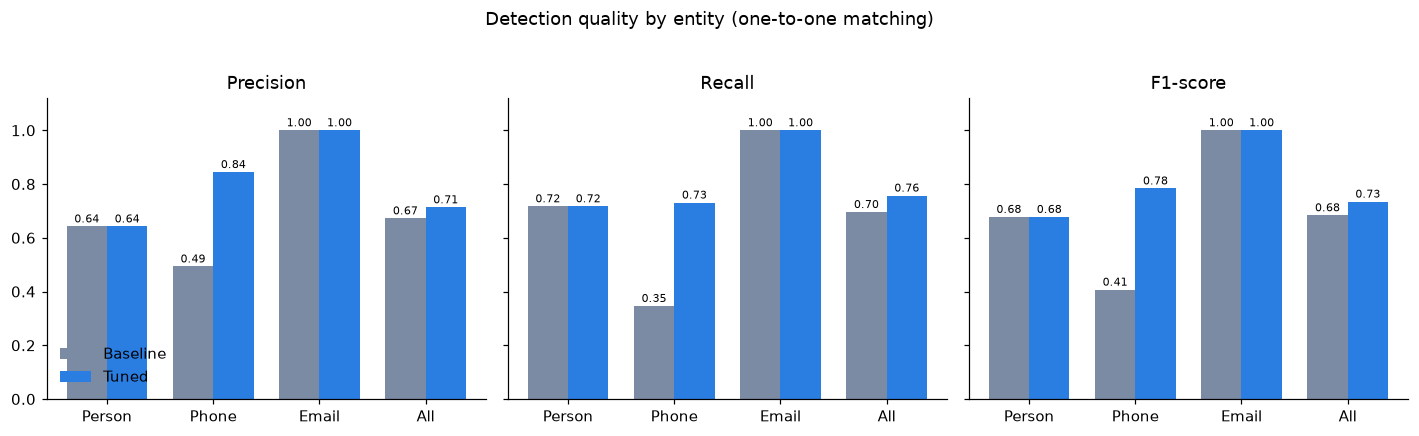

In [3]:
ents = ["PERSON","PHONE_NUMBER","EMAIL_ADDRESS","ALL"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
x = np.arange(len(ents)); w = 0.38
for ax, metric in zip(axes, ["precision","recall","f1"]):
    ax.bar(x-w/2, [o2o[(metric,"baseline")][e] for e in ents], w, label="Baseline", color=BASE)
    ax.bar(x+w/2, [o2o[(metric,"tuned")][e] for e in ents], w, label="Tuned", color=TUNED)
    for i,e in enumerate(ents):
        ax.text(i-w/2, o2o[(metric,"baseline")][e]+0.015, f"{o2o[(metric,'baseline')][e]:.2f}", ha="center", fontsize=7)
        ax.text(i+w/2, o2o[(metric,"tuned")][e]+0.015, f"{o2o[(metric,'tuned')][e]:.2f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(["Person","Phone","Email","All"])
    ax.set_title(metric.capitalize() if metric!="f1" else "F1-score"); ax.set_ylim(0, 1.12)
axes[0].legend(frameon=False, loc="lower left")
plt.suptitle("Detection quality by entity (one-to-one matching)", y=1.03)
plt.tight_layout(); plt.show()

### Sensitivity to the matching rule

Detection scores depend heavily on how a predicted span is judged "correct". The README reports the strict **one-to-one** numbers; **overlap** is more lenient (any overlap counts) and **exact** requires identical boundaries. Reporting all three makes the results easier to interpret honestly.

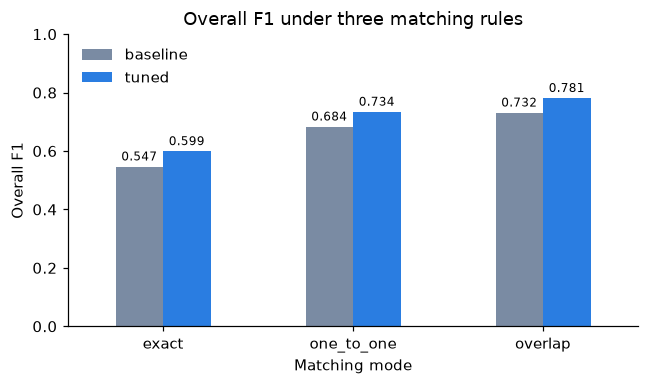

config,baseline,tuned
mode,,
exact,0.5470,0.5994
one_to_one,0.6837,0.7344
overlap,0.7316,0.7814


In [4]:
allrows = m[m["entity"]=="ALL"].pivot(index="mode", columns="config", values="f1").loc[["exact","one_to_one","overlap"]]
ax = allrows.plot(kind="bar", color=[BASE, TUNED], figsize=(6,3.6), rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0,1); ax.set_ylabel("Overall F1"); ax.set_xlabel("Matching mode")
ax.set_title("Overall F1 under three matching rules"); ax.legend(frameon=False, title=None)
plt.tight_layout(); plt.show()
allrows.round(4)

In [5]:
comp = pd.read_csv(RESULTS/"detection_comparison.csv")
comp["F1 gain"] = (comp["f1_tuned"] - comp["f1_baseline"]).round(4)
comp

,entity,precision_baseline,recall_baseline,f1_baseline,precision_tuned,recall_tuned,f1_tuned,F1 gain
0,PERSON,0.6422,0.7171,0.6776,0.6422,0.7171,0.6776,0.0000
1,PHONE_NUMBER,0.4932,0.3462,0.4068,0.8444,0.7308,0.7835,0.3767
2,EMAIL_ADDRESS,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
3,ALL,0.6721,0.6957,0.6837,0.7133,0.7569,0.7344,0.0507


**Reading the table.** Email detection is perfect for both configurations (regex-based and unambiguous). The tuning only affects phone numbers, where F1 rises from 0.41 to 0.78 mainly because precision rose from 0.49 to 0.84 and recall from 0.35 to 0.73. This is consistent with the two tuning rules (an added IMEI-format recognizer, and suppression of IPv4 addresses mis-flagged as phones), though the notebook does not break the gain down by rule. **Person detection is unchanged at F1 0.68** (it uses spaCy NER, which the tuning does not touch) and is the weakest remaining link. Note that the one-to-one rule penalises PERSON because the dataset labels first and last names separately; under the lenient overlap rule PERSON F1 is 0.74 (see `detection_comparison` / `metrics_*.csv`).

## 2. Missed-PII analysis

A missed (false-negative) entity can stay in the output **in clear text**, the most direct leakage risk of the pipeline. How many entities count as "missed" depends on the matching rule, so two bounds are shown:

- **Strict (one-to-one)**: the number the README reports (199 / 159). Each prediction can match only one annotated span. The dataset labels first and last names separately, so when Presidio returns one span for a full name, only one of the two labels counts as found (see `test_one_to_one_prevents_double_counting`). This **overstates** real leakage for PERSON.
- **Lenient (overlap)**: a gold span counts as found if any prediction touches it. This **understates** leakage when only part of an entity is redacted.

True exposure lies somewhere between the two.

In [6]:
rows = []
for cfg in ["baseline", "tuned"]:
    for ent in ["PERSON","PHONE_NUMBER","EMAIL_ADDRESS","ALL"]:
        g = m[(m.config==cfg)&(m.entity==ent)&(m["mode"]=="one_to_one")].iloc[0]
        l = m[(m.config==cfg)&(m.entity==ent)&(m["mode"]=="overlap")].iloc[0]
        rows.append(dict(config=cfg, entity=ent, gold=int(g.gold),
                         missed_strict=int(g.gold-g.found_gold), missed_lenient=int(l.gold-l.found_gold)))
miss = pd.DataFrame(rows)
miss["strict_%"]  = (100*miss.missed_strict/miss.gold).round(2)
miss["lenient_%"] = (100*miss.missed_lenient/miss.gold).round(2)
miss

,config,entity,gold,missed_strict,missed_lenient,strict_%,lenient_%
0,baseline,PERSON,463,131,61,28.29,13.17
1,baseline,PHONE_NUMBER,104,68,68,65.38,65.38
2,baseline,EMAIL_ADDRESS,87,0,0,0.00,0.00
3,baseline,ALL,654,199,129,30.43,19.72
4,tuned,PERSON,463,131,61,28.29,13.17
5,tuned,PHONE_NUMBER,104,28,28,26.92,26.92
6,tuned,EMAIL_ADDRESS,87,0,0,0.00,0.00
7,tuned,ALL,654,159,89,24.31,13.61


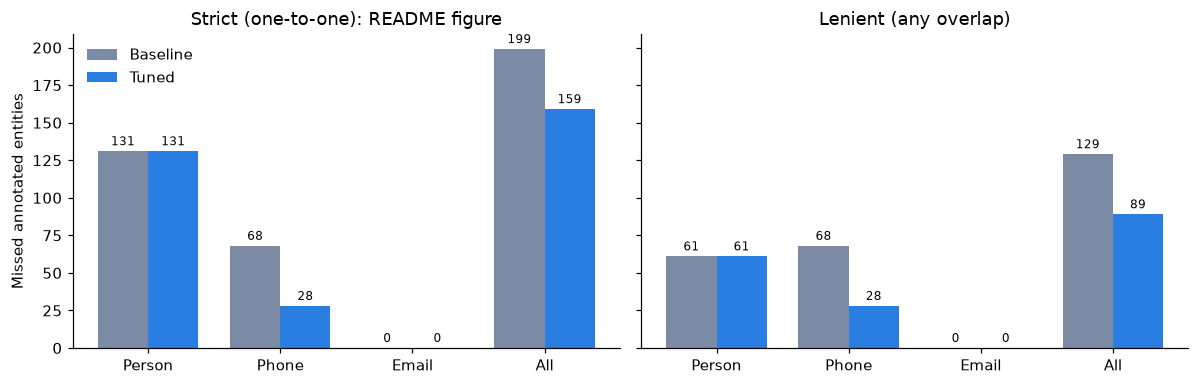

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, title in zip(axes, ["missed_strict","missed_lenient"],
                          ["Strict (one-to-one): README figure","Lenient (any overlap)"]):
    b = [miss[(miss.config=="baseline")&(miss.entity==e)][col].item() for e in ents]
    t = [miss[(miss.config=="tuned")&(miss.entity==e)][col].item() for e in ents]
    ax.bar(x-w/2, b, w, label="Baseline", color=BASE); ax.bar(x+w/2, t, w, label="Tuned", color=TUNED)
    ax.bar_label(ax.containers[0], padding=2, fontsize=8); ax.bar_label(ax.containers[1], padding=2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(["Person","Phone","Email","All"]); ax.set_title(title)
axes[0].set_ylabel("Missed annotated entities"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

Tuning removed **40** missed phone numbers under the strict rule (199 → 159) and the same 40 under the lenient rule (129 → 89); person and email misses did not change. After tuning, the share of annotated entities left exposed is **between about 13.6% (lenient) and 24.3% (strict)**. Either way a substantial fraction can remain visible, so the pipeline should not be presented as complete de-identification. These are miss rates on a labelled synthetic benchmark, **not** measured real-world leakage rates.

## 3. Spark throughput benchmark

10,000 records, 16 input partitions, local mode with 1 vs 2 cores, 3 runs each. Wall time includes Spark start-up and per-worker Presidio/spaCy model loading.

In [8]:
runs = []
for i, f in enumerate(["throughput_10000.csv","throughput_10000_run2.csv","throughput_10000_run3.csv"], 1):
    d = pd.read_csv(RESULTS/f); d["run"] = i; runs.append(d)
runs = pd.concat(runs)
print("Per-run results")
display(runs[["run","cores","rows","wall_seconds","rows_per_sec"]].reset_index(drop=True))

summ = runs.groupby("cores")["rows_per_sec"].agg(["mean","std"]).round(2)
summ["mean_wall_s"] = runs.groupby("cores")["wall_seconds"].mean().round(1)
summ["speedup"] = (summ["mean"]/summ["mean"].iloc[0]).round(3)
summ["parallel_efficiency_%"] = (100*summ["speedup"]/summ.index.to_series()).round(1)
summ

Per-run results


,run,cores,rows,wall_seconds,rows_per_sec
0,1,1,10000,189.2,52.87
1,1,2,10000,169.9,58.85
2,2,1,10000,193.5,51.68
3,2,2,10000,181.9,54.98
4,3,1,10000,199.4,50.14
5,3,2,10000,167.4,59.73


,mean,std,mean_wall_s,speedup,parallel_efficiency_%
cores,,,,,
1,51.56,1.37,194.0,1.000,100.0
2,57.85,2.53,173.1,1.122,56.1


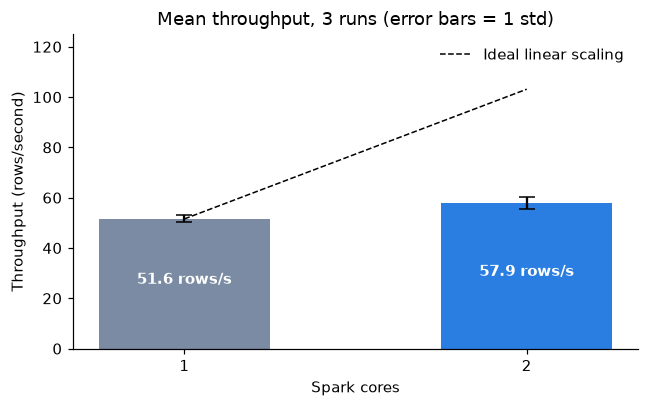

In [9]:
fig, ax = plt.subplots(figsize=(6,3.8))
cores = summ.index.tolist()
ax.bar([str(c) for c in cores], summ["mean"], yerr=summ["std"], capsize=5, color=[BASE, TUNED], width=0.5)
for i,(mu,sd) in enumerate(zip(summ["mean"], summ["std"])):
    ax.text(i, mu/2, f"{mu:.1f} rows/s", ha="center", fontsize=10, color="white", fontweight="bold")
# ideal linear scaling reference
ax.plot([0,1],[summ["mean"].iloc[0], summ["mean"].iloc[0]*2], "k--", lw=1, label="Ideal linear scaling")
ax.set_xlabel("Spark cores"); ax.set_ylabel("Throughput (rows/second)")
ax.set_title("Mean throughput, 3 runs (error bars = 1 std)"); ax.set_ylim(0, 125); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.** Two cores gave a ~**1.12× speedup** (~56% parallel efficiency), far from linear. Plausible causes: fixed Spark start-up cost counted in wall time, loading the spaCy `en_core_web_lg` model separately in each Python worker, and a small, local, single-machine setup. Note also that the run-to-run spread (e.g. 1.06× to 1.19× speedup across runs) is of similar size to the effect itself, so with only three runs the true speedup is uncertain. These numbers describe this machine and workload only.

## 4. Privacy-risk experiments

All three use **synthetic** data and are small, illustrative demonstrations, not estimates of real-world attack success.

In [10]:
sec = pd.read_csv(RESULTS/"security_experiments.csv")
sec

,experiment,scenario,total,successful,rate_percent
0,Dictionary attack,Correct secret key,5,4,80.00
1,Dictionary attack,Incorrect secret key,5,0,0.00
2,Missed PII detection,Baseline,654,199,30.43
3,Missed PII detection,Tuned,654,159,24.31
4,Linkage attack,Unique matches,3,2,66.67


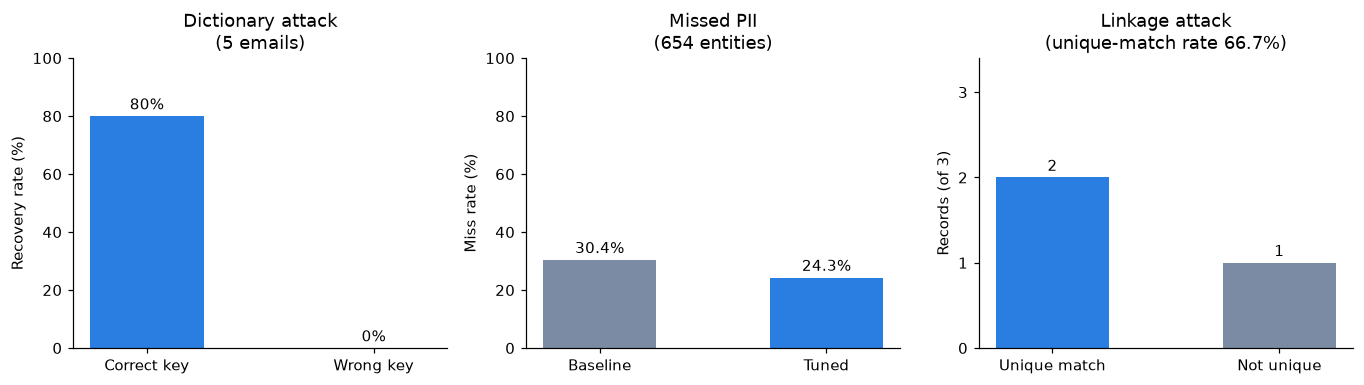

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
d = sec[sec.experiment=="Dictionary attack"]
axes[0].bar(["Correct key","Wrong key"], d["rate_percent"], color=[TUNED, BASE], width=0.5)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%", padding=2)
axes[0].set_title("Dictionary attack\n(5 emails)"); axes[0].set_ylim(0,100); axes[0].set_ylabel("Recovery rate (%)")

mm = sec[sec.experiment=="Missed PII detection"]
axes[1].bar(mm["scenario"], mm["rate_percent"], color=[BASE, TUNED], width=0.5)
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=2)
axes[1].set_title("Missed PII\n(654 entities)"); axes[1].set_ylim(0,100); axes[1].set_ylabel("Miss rate (%)")

l = sec[sec.experiment=="Linkage attack"].iloc[0]
axes[2].bar(["Unique match","Not unique"], [l.successful, l.total-l.successful], color=[TUNED, BASE], width=0.5)
axes[2].bar_label(axes[2].containers[0], padding=2)
axes[2].set_title(f"Linkage attack\n(unique-match rate {l.rate_percent:.1f}%)"); axes[2].set_ylabel("Records (of 3)")
axes[2].set_yticks([0,1,2,3]); axes[2].set_ylim(0,3.4)
plt.tight_layout(); plt.show()

### 4.1 Reproducing the experiments from the repo's own code

The numbers in `security_experiments.csv` for the dictionary and linkage attacks come from `evaluate_dictionary_attack` and `linkage_attack` in `src/pii_pipeline/reidentify.py` (the inputs are defined in `tests/test_token.py`). The cells below re-run them, so you can see how "4 of 5" and "2 of 3" arise. These functions use only the standard library and pandas, so no Presidio or Spark is needed.

In [12]:
import sys
sys.path.insert(0, str(next(p for p in [Path("../src"), Path("src")] if p.exists())))
from pii_pipeline.reidentify import make_token, evaluate_dictionary_attack, linkage_attack

# --- Dictionary attack (inputs from tests/test_token.py) ---
originals  = ["alice@example.com","bob@example.com","charlie@example.com","david@example.com","eve@example.com"]
candidates = originals[:4]              # attacker's guess list contains only 4 of the 5 targets
KEY, WRONG = b"experiment-only-secret", b"attacker-wrong-secret"

ok_n, ok_rate = evaluate_dictionary_attack(originals, candidates, KEY, KEY)
bad_n, bad_rate = evaluate_dictionary_attack(originals, candidates, KEY, WRONG)
print(f"Attacker WITH the key : {ok_n}/5 recovered ({ok_rate:.0f}%)")
print(f"Attacker WRONG key    : {bad_n}/5 recovered ({bad_rate:.0f}%)")
print("Not recovered:", [o for o in originals if o not in candidates], "(never in the candidate list)")

# --- Linkage attack (inputs from tests/test_token.py) ---
pseudo = pd.DataFrame([
    {"token":"P001","city":"Bengaluru","age":27,"job":"Architect"},
    {"token":"P002","city":"Mysuru","age":35,"job":"Teacher"},
    {"token":"P003","city":"Bengaluru","age":27,"job":"Engineer"}])
aux = pd.DataFrame([
    {"name":"Alice","city":"Bengaluru","age":27,"job":"Architect"},
    {"name":"Bob","city":"Mysuru","age":35,"job":"Teacher"},
    {"name":"Charlie","city":"Bengaluru","age":27,"job":"Engineer"},
    {"name":"David","city":"Bengaluru","age":27,"job":"Engineer"}])
qi = ["city","age","job"]
uniq, total, rate = linkage_attack(pseudo, aux, qi)
print(f"Linkage: {uniq}/{total} records uniquely matched ({rate:.2f}%)")

detail = pseudo.merge(aux.groupby(qi)["name"].agg(list).reset_index(), on=qi, how="left")
detail["candidates"] = detail["name"].apply(len)
detail.rename(columns={"name":"matching identities"})

Attacker WITH the key : 4/5 recovered (80%)
Attacker WRONG key    : 0/5 recovered (0%)
Not recovered: ['eve@example.com'] (never in the candidate list)
Linkage: 2/3 records uniquely matched (66.67%)


,token,city,age,job,matching identities,candidates
0,P001,Bengaluru,27,Architect,[Alice],1
1,P002,Mysuru,35,Teacher,[Bob],1
2,P003,Bengaluru,27,Engineer,"[Charlie, David]",2


In [13]:
# Cross-check against the saved results file
d = sec[sec.experiment=="Dictionary attack"].set_index("scenario")
l = sec[sec.experiment=="Linkage attack"].iloc[0]
assert ok_n == d.loc["Correct secret key","successful"] and bad_n == d.loc["Incorrect secret key","successful"]
assert uniq == l.successful and total == l.total and round(rate,2) == l.rate_percent
print("Live re-run matches security_experiments.csv")

Live re-run matches security_experiments.csv


**What this shows**
- **Dictionary attack:** the attacker with the key recovers every email that is in their candidate list, so the 80% is set by the experiment's design (4 of 5 targets were guessable), not by the strength of the attack. With the wrong key nothing is recovered. This is a key-management risk, not a break of HMAC.
- **Linkage attack:** with no names at all, `city + age + job` identifies Alice (P001) and Bob (P002) uniquely. P003 stays ambiguous only because two people (Charlie and David) share the same attributes.
- Both are toy examples (5 and 3 records) and do not estimate real-world risk.

### 4.2 Pseudonymization example (illustrative)

Rendered from the README example; running the real pipeline requires Presidio and `PSEUDO_SECRET` (see README).

In [14]:
DEMO_KEY = b"demo-only-secret"
print("Original      : Contact alice@example.com for assistance.")
print("Pseudonymized : Contact", make_token("EMAIL_ADDRESS", "alice@example.com", DEMO_KEY), "for assistance.")

Original      : Contact alice@example.com for assistance.
Pseudonymized : Contact <EMAIL_ADDRESS_344b19aa76> for assistance.


## 5. Key takeaways

| Question | Answer |
|---|---|
| Did tuning help? | Yes: overall F1 0.684 → 0.734 (one-to-one); phone F1 0.41 → 0.78. Person and email unchanged. |
| What's the weakest point? | Person-name detection (F1 0.68), and the 13.6% to 24.3% of annotated entities still missed after tuning (lenient vs strict matching). |
| Does Spark scale? | Modestly: 1.12× on 2 cores with high run-to-run variance. |
| Is pseudonymization enough? | No. Missed PII stays in clear text, tokens stay linkable, quasi-identifiers can single out records, and key exposure enables dictionary attacks. |

**Caveats.** One dataset (synthetic, English), one random sample (seed 42), three throughput runs, and toy-sized attack experiments. The percentages from the three privacy experiments measure different things and should not be compared with each other.